# Petit exemple deterministe a une unite (section 5.1 de l'article)

Ce notebook reproduit, dans l'ordre, les chiffres et les affirmations du texte de la section 5.1 (`small_example.tex`),
chacun etant verifie par un `@assert` :

1. l'instance (tableau 1) : **un groupe**, **T = 6** periodes d'une heure, initialement eteint, demande **deterministe**
   (`S = 1`, `force = 0` : l'arbre de scenarios se reduit a un chemin) ; le delestage et la surproduction coutent
   700 par MWh (constantes `SHEDDING_COST` et `CURTAILEMENT_COST` du package) ;
2. l'optimum exact (80 200), son planning `[1:7]` et sa trajectoire de production ;
3. la convergence de la borne (tableau 2) : **2 coupes** a la racine pour l'intervalle, **6** pour la 3-bin ;
4. les premieres coupes a la racine, construites au meme planning (tout eteint), et leur comparaison.

**Convention de comptage.** La borne `L_k` de l'iteration `k` est la valeur du probleme racine avec les `k-1` coupes
des iterations precedentes. Une formulation « atteint l'optimum apres `n` coupes » si `L_{n+1}` est l'optimum.

In [1]:
using MSUC, Gurobi, Printf, Random, LinearAlgebra, Plots

GRB_ENV = Gurobi.Env()
# Threads et Seed fixes : le MIP racine a des solutions optimales multiples, ces reglages rendent les
# plannings (donc le nombre d'iterations) reproductibles. OutputFlag en premier : sinon Gurobi annonce
# chaque parametre a chaque modele cree.
solveur(seed = 0) = optimizer_with_attributes(() -> Gurobi.Optimizer(GRB_ENV), "OutputFlag" => 0, "Threads" => 1, "Seed" => seed)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


solveur (generic function with 2 methods)

## L'instance (tableau 1)

Le groupe est decrit par ses productions minimale `Pmin` et maximale `Pmax`, sa rampe `R` (montante et descendante),
son cout lineaire `c`, son cout fixe (par periode allumee), son cout de demarrage, et sa duree minimale de marche.
Dans le code `S^U = S^D = Pmin` : le groupe demarre et s'arrete a `Pmin`. Les durees minimales de marche et d'arret
valent 1 : aucune restriction. Les intervalles d'exploitation `[a, b]` sont les periodes `a, ..., b-1` ou le groupe est allume
(`b = T+1` : jusqu'a la fin de l'horizon).

In [2]:
T = 6
DEMANDE = [90.0, 80.0, 130.0, 60.0, 100.0, 90.0]
FORCE = 0.0                       # 0 : deterministe

# pmin, pmax, rampe, cout lineaire, cout fixe (par periode allumee), cout de demarrage, duree minimale de marche
function unite(nom; pmin, pmax, rampe, cout, fixe, demarrage, minup)
    return MSUC.ThermalUnit(
        nom, 1,                # nom, noeud du reseau
        pmin, pmax,            # production minimale, maximale
        rampe, rampe,          # rampes montante, descendante
        demarrage, 0.0,        # cout de demarrage, d'arret
        cout, fixe,            # cout lineaire, cout fixe
        0.0, -1,               # production et statut initiaux : eteinte
        minup, 1,              # duree minimale d'allumage, d'arret
        MSUC.set_intervals(minup, -1, 0.0, pmin, rampe, T),
    )
end

unites = [unite(1; pmin = 40.0, pmax = 100.0, rampe = 30.0, cout = 20.0, fixe = 50.0, demarrage = 500.0, minup = 1)]
instance = MSUC.Instance("small_example", T, length(unites), unites, MSUC.IntervalIndex(unites),
    Dict{Tuple{Int,Int},MSUC.Line}(), [Int[]], [DEMANDE], MSUC.ARMAProcess(1; S = 1), solveur())
N = instance.N
unit = unites[1]

println("limites techniques (MW) : Pmin = $(unit.MinPower), Pmax = $(unit.MaxPower), R^U = R^D = $(unit.DeltaRampUp), S^U = S^D = $(unit.MinPower)")
println("couts : generation c = $(unit.LinearTerm) par MWh, fixe = $(unit.ConstTerm) par periode allumee, ",
        "demarrage = $(unit.StartUpCost), arret = $(unit.StartDownCost)")
println("cout de delestage et de surproduction : $(MSUC.SHEDDING_COST) et $(MSUC.CURTAILEMENT_COST) par MWh ; ",
        "$(length(unit.intervals)) intervalles d'exploitation")
println("\nperiode t  ", join([@sprintf("%5d", t) for t in 1:T]))
println("demande    ", join([@sprintf("%5.0f", d) for d in DEMANDE]))

limites techniques (MW) : Pmin = 40.0, Pmax = 100.0, R^U = R^D = 30.0, S^U = S^D = 40.0
couts : generation c = 20.0 par MWh, fixe = 50.0 par periode allumee, demarrage = 500.0, arret = 0.0
cout de delestage et de surproduction : 700.0 et 700.0 par MWh ; 21 intervalles d'exploitation

periode t      1    2    3    4    5    6
demande       90   80  130   60  100   90


## Optimum exact, planning optimal et trajectoire de production

La formulation extensive (`multistage_extensive`) donne l'optimum exact du probleme deterministe, auquel les deux
bornes doivent converger. Pour la trajectoire de production du planning optimal, on resout le LP de dispatch
a planning fixe, avec les memes contraintes de capacite et de rampes que le code (`add_unit_dynamics!`) ;
on verifie que son cout est la valeur future exacte donnee par la formulation extensive, et que la trajectoire est unique.

In [3]:
# intervalles [a, b] a partir du statut aux periodes 0, ..., T : allumee aux periodes a, ..., b-1
function intervalles(statut)
    res = Tuple{Int,Int}[]
    t = 0
    while t < length(statut)
        if statut[t + 1] > 0.5
            a = t
            while t < length(statut) && statut[t + 1] > 0.5
                t += 1
            end
            push!(res, (a, t))
        else
            t += 1
        end
    end
    return res
end
texte(ints) = isempty(ints) ? "tout eteint" : join(["[$a:$b]" for (a, b) in ints], " ")

# planning (u, v, w, intervalles choisis) a partir d'une liste d'intervalles (j, a, b) : u_t = somme des gamma_{a,b} avec a <= t < b
function planning_depuis_intervalles(choisis)
    u, v, w = zeros(N, T + 1), zeros(N, T), zeros(N, T)
    for (j, a, b) in choisis
        for t in max(a, 0):min(b - 1, T)
            u[j, t + 1] = 1
        end
        a >= 1 && (v[j, a] = 1)
        b <= T && (w[j, b] = 1)
    end
    ids = sort([instance.intervals.id[c] for c in choisis])
    return MSUC.Schedule(u, v, w, ids, [instance.intervals.unit[id] for id in ids])
end

# valeur future exacte V*(x) : cout optimal de dispatch du planning, par la formulation extensive avec planning fixe
function valeur_exacte(choisis)
    gamma = Dict((u.name, a, b) => Float64((u.name, a, b) in choisis) for u in unites for (a, b) in u.intervals)
    res = MSUC.multistage_extensive(instance; force = FORCE, gap = 1e-9, timelimit = 60, res_gamma = gamma)
    return res[1] - MSUC.schedule_commitment_cost(instance, planning_depuis_intervalles(choisis))
end

# LP de dispatch du groupe pour un planning donne : production, delestage, surproduction, cout, et unicite de la production
function dispatch_optimal(choisis)
    p = planning_depuis_intervalles(choisis)
    m = Model(solveur())
    @variable(m, y[0:T] >= 0)
    @variable(m, delestage[1:T] >= 0)
    @variable(m, surplus[1:T] >= 0)
    fix(y[0], unit.InitialPower; force = true)
    for t in 1:T
        MSUC.add_unit_dynamics!(m, unit, y[t], y[t - 1], p.u[1, t + 1], p.u[1, t], p.v[1, t], p.w[1, t])
    end
    @constraint(m, [t in 1:T], y[t] - surplus[t] + delestage[t] == DEMANDE[t])
    cout = sum(unit.LinearTerm * y[t] + MSUC.SHEDDING_COST * delestage[t] + MSUC.CURTAILEMENT_COST * surplus[t] for t in 1:T)
    @objective(m, Min, cout)
    optimize!(m)
    val = objective_value(m)
    ystar = [value(y[t]) for t in 1:T]
    res = (y = ystar, delestage = [value(delestage[t]) for t in 1:T], surplus = [value(surplus[t]) for t in 1:T],
           cout = val, unique = true)
    # unicite : sous la contrainte de cout optimal, aucune production y_t ne peut etre ni plus petite ni plus grande
    @constraint(m, cout <= val + 1e-6)
    for t in 1:T, sens in (MOI.MIN_SENSE, MOI.MAX_SENSE)
        set_objective_function(m, y[t])
        set_objective_sense(m, sens)
        optimize!(m)
        abs(objective_value(m) - ystar[t]) > 1e-6 && return merge(res, (unique = false,))
    end
    return res
end

exact = MSUC.multistage_extensive(instance; force = FORCE, gap = 1e-9, timelimit = 60)
opt = exact[1]
optimal = [(1, a, b) for (a, b) in intervalles([exact[4][1][1, t] for t in 0:T])]
x_opt = planning_depuis_intervalles(optimal)
engagement = MSUC.schedule_commitment_cost(instance, x_opt)
disp = dispatch_optimal(optimal)

@printf("optimum exact = %.1f\nplanning optimal : %s\n", opt, texte([(a, b) for (_, a, b) in optimal]))
@printf("production y*_t = %s MW  (trajectoire unique : %s)\n", join([@sprintf("%.0f", y) for y in disp.y], ", "), disp.unique)
@printf("demande non servie = %.0f MWh, surproduction = %.0f MWh\n", sum(disp.delestage), sum(disp.surplus))
@printf("cout total = %.0f = %.0f (engagement) + %.0f (dispatch)\n", opt, engagement, disp.cout)

# valeurs du texte
@assert optimal == [(1, 1, 7)] && all(isapprox.(disp.y, [40, 70, 100, 70, 100, 90]))
@assert sum(disp.delestage) == 90 && sum(disp.surplus) == 10
@assert isapprox(opt, 80200) && isapprox(engagement, 800) && isapprox(disp.cout, 79400) && disp.unique
@assert isapprox(disp.cout, valeur_exacte(optimal))        # LP de dispatch = formulation extensive a planning fixe

Set parameter Seed to value 0
Set parameter Threads to value 1
optimum exact = 80200.0
planning optimal : [1:7]
production y*_t = 40, 70, 100, 70, 100, 90 MW  (trajectoire unique : true)
demande non servie = 90 MWh, surproduction = 10 MWh
cout total = 80200 = 800 (engagement) + 79400 (dispatch)


## Convergence de la borne inferieure (tableau 2)

Les deux algorithmes partent de l'approximation nulle. On entraine chaque formulation et on releve la borne `L_k` du
probleme racine a l'iteration `k`, calculee avec les `k-1` coupes des passes arriere precedentes, ainsi que le
planning `x^k` du probleme racine. Une etoile marque la premiere iteration ou la borne atteint l'optimum.

In [4]:
K = 7        # de quoi voir la convergence de la 3-bin (a augmenter si le solveur change)

# renvoie le modele, les bornes L_k et les plannings x^k de chaque iteration
function entraine(builder, method; iterations = K, seed = 0)
    model = MSUC.PolicyGraph(builder, instance, FORCE, MSUC.Graph(T + 1), method;
                             lower_bound = 0.0, optimizer = solveur(seed))
    plannings = MSUC.Schedule[]
    Random.seed!(MSUC.SEED)
    MSUC.train(model; iteration_limit = iterations, mip_gap = 1e-9, print_level = 0,
               run_numerical_stability_report = false,
               post_iteration_callback = result -> push!(plannings, model.schedule))
    bornes = [l.bound for l in model.most_recent_training_results.log]
    return (model = model, bornes = bornes, plannings = plannings)
end

# premiere iteration k ou la borne atteint l'optimum : n = k - 1 coupes suffisent
premiere_iteration(bornes) = findfirst(b -> b >= opt - 1e-6, bornes)
coupes_necessaires(bornes) = (k = premiere_iteration(bornes); k === nothing ? nothing : k - 1)

ext = entraine(MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation)
bin3 = entraine(MSUC.subproblem_builder_UC_def, MSUC.SDDPFormulation)

function ligne(nom, bornes)
    k0 = premiere_iteration(bornes)
    return @sprintf("%-14s", nom) * join([@sprintf("%9.0f%s", b, k == k0 ? "*" : " ") for (k, b) in enumerate(bornes)])
end
println("iteration k   ", join([@sprintf("%9d ", k) for k in 1:K]))
println(ligne("L_k 3-bin", bin3.bornes))
println(ligne("L_k intervalle", ext.bornes))
@printf("\nnombre de coupes pour atteindre l'optimum : intervalle %s, 3-bin %s\n",
        coupes_necessaires(ext.bornes), coupes_necessaires(bin3.bornes))

# valeurs du texte
@assert round.(Int, ext.bornes) == [0, 39000, 80200, 80200, 80200, 80200, 80200]
@assert round.(Int, bin3.bornes) == [0, 800, 73172, 79472, 79522, 80178, 80200]
@assert coupes_necessaires(ext.bornes) == 2 && coupes_necessaires(bin3.bornes) == 6

iteration k           1         2         3         4         5         6         7 
L_k 3-bin             0       800     73172     79472     79522     80178     80200*
L_k intervalle        0     39000     80200*    80200     80200     80200     80200 

nombre de coupes pour atteindre l'optimum : intervalle 2, 3-bin 6


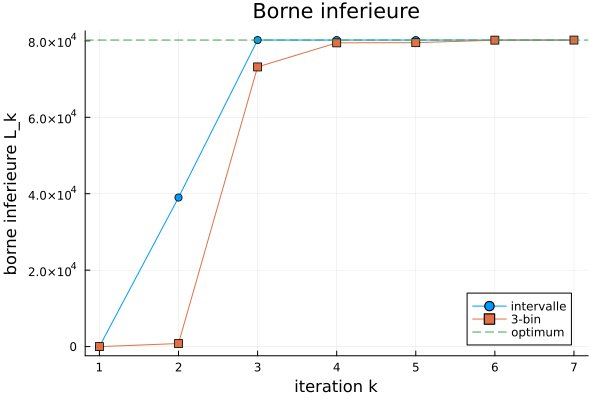

In [5]:
plot(1:K, ext.bornes, label = "intervalle", marker = :circle, xlabel = "iteration k", ylabel = "borne inferieure L_k",
     title = "Borne inferieure", legend = :bottomright)
plot!(1:K, bin3.bornes, label = "3-bin", marker = :square)
hline!([opt], label = "optimum", linestyle = :dash)

## La premiere iteration : le planning tout eteint

Sans coupe, le probleme racine ne minimise que le cout d'engagement ; les couts fixes et de demarrage etant
positifs, sa seule solution est le planning tout eteint, dans les deux formulations : les premieres coupes sont
construites au meme planning `x^1`. Tout eteint, toute la demande est delestee, donc le cout de dispatch vaut
`700 sum_t d_t`.

Un planning est represente indifferemment par `x = (u, v, w)` ou par les variables d'intervalles `gamma` : choisir
`gamma_{a,b} = 1` allume le groupe de `a` a `b-1`, donc `u_t = sum_{[a:b], a <= t < b} gamma_{a,b}`.

In [6]:
tout_eteint = Tuple{Int,Int,Int}[]
@assert ext.plannings[1].x == bin3.plannings[1].x && all(iszero, ext.plannings[1].x)     # meme planning x^1 : tout eteint
cout_eteint = valeur_exacte(tout_eteint)
@printf("cout de dispatch du planning tout eteint = %.0f ; 700 x demande totale = %.0f\n",
        cout_eteint, MSUC.SHEDDING_COST * sum(DEMANDE))
@assert isapprox(cout_eteint, 385000) && isapprox(cout_eteint, MSUC.SHEDDING_COST * sum(DEMANDE))

# lien x = x(gamma) dans le code : u_t = somme des gamma_{a,b} des intervalles choisis qui couvrent t, a chaque iteration
u_depuis_gamma(p) = [count(id -> instance.intervals.a[id] <= t < instance.intervals.b[id], p.selected) for t in 1:T]
@assert all(u_depuis_gamma(p) == p.u[1, 2:end] for p in ext.plannings)
println("x = x(gamma) verifie aux ", K, " plannings de l'intervalle")

cout de dispatch du planning tout eteint = 385000 ; 700 x demande totale = 385000
x = x(gamma) verifie aux 7 plannings de l'intervalle


### Les premieres coupes a la racine

`cut^{3b,2}_1(x) = 385 000 - 68 000 sum_t u_t` et `cut^{ext,2}_1(gamma) = 385 000 + sum_{[a:b]} tau_{a,b} gamma_{a,b}`, avec
`tau_{a,b} = -(700 - c) sum_{t=a}^{b-1} ybar_{a,b,t}`, ou `ybar` est la production maximale atteignable de l'intervalle
(`reference_output` dans le code). Le coefficient 3-bin `-(700 - c) Pmax = -68 000` ne depend que de la longueur de
l'intervalle ; comme `ybar <= Pmax`, `tau_{a,b} >= -68 000 (b - a)` : la premiere coupe intervalle est au moins aussi forte
que la premiere coupe 3-bin a tout planning admissible.

In [7]:
coupe_3b = bin3.model[1].cuts[2]          # [1] : coupe triviale theta >= 0, [k+1] : coupe de l'iteration k
coupe_int = ext.model[1].cuts[2]
prix = MSUC.SHEDDING_COST - unit.LinearTerm                     # 700 - c

# coefficients de la coupe 3-bin sur u (periodes 1, ..., T), v et w, sur y_0 et sur zeta_0
tu = [coupe_3b.tau[MSUC.u_index(instance, 1, t)] for t in 1:T]
tv = [coupe_3b.tau[MSUC.v_index(instance, 1, t)] for t in 1:T]
tw = [coupe_3b.tau[MSUC.w_index(instance, 1, t)] for t in 1:T]
@printf("constante : 3-bin %.0f, intervalle %.0f\n", coupe_3b.alpha, coupe_int.alpha)
@printf("3-bin : coefficient de u_t = %s ; v et w nuls : %s ; y_0 et zeta_0 nuls : %s\n",
        join(unique(tu), ", "), all(iszero, tv) && all(iszero, tw),
        all(iszero, coupe_3b.beta) && all(iszero, coupe_3b.delta))
@assert coupe_3b.alpha == coupe_int.alpha == 385000
@assert all(tu .== -prix * unit.MaxPower) && -prix * unit.MaxPower == -68000 && all(iszero, tv) && all(iszero, tw)
@assert all(iszero, coupe_3b.beta) && all(iszero, coupe_3b.delta) && all(iszero, coupe_int.delta)

ybar(a, b, t) = MSUC.reference_output(unit, a, b, t, T)                       # production maximale atteignable
tau_tilde(a, b) = -prix * sum(ybar(a, b, t) for t in a:(b - 1))              # coefficient de [a:b], par la formule du texte
tau_int(a, b) = coupe_int.tau[instance.intervals.id[(1, a, b)]]              # coefficient stocke dans la coupe intervalle

@assert all(isapprox(tau_int(a, b), tau_tilde(a, b)) for (a, b) in unit.intervals)       # formule du texte
@assert all(ybar(a, b, t) <= unit.MaxPower for (a, b) in unit.intervals for t in a:(b - 1))
@assert all(tau_int(a, b) >= -prix * unit.MaxPower * (b - a) - 1e-6 for (a, b) in unit.intervals)
println("coefficient de [a:b] : intervalle (entre crochets : -68 000 (b - a), coefficient 3-bin du meme intervalle)")
println("      ", join([@sprintf("%19s", "b = $b") for b in 2:(T + 1)]))
for a in 1:T
    print("a = $a ")
    for b in 2:(T + 1)
        print([a, b] in unit.intervals ? @sprintf("%9.0f [%7.0f]", tau_int(a, b), -prix * unit.MaxPower * (b - a)) : " "^19)
    end
    println()
end

constante : 3-bin 385000, intervalle 385000
3-bin : coefficient de u_t = -68000.0 ; v et w nuls : true ; y_0 et zeta_0 nuls : true
coefficient de [a:b] : intervalle (entre crochets : -68 000 (b - a), coefficient 3-bin du meme intervalle)
                    b = 2              b = 3              b = 4              b = 5              b = 6              b = 7
a = 1    -27200 [ -68000]   -54400 [-136000]  -102000 [-204000]  -149600 [-272000]  -217600 [-340000]  -346800 [-408000]
a = 2                       -27200 [ -68000]   -54400 [-136000]  -102000 [-204000]  -149600 [-272000]  -278800 [-340000]
a = 3                                          -27200 [ -68000]   -54400 [-136000]  -102000 [-204000]  -210800 [-272000]
a = 4                                                             -27200 [ -68000]   -54400 [-136000]  -142800 [-204000]
a = 5                                                                                -27200 [ -68000]   -74800 [-136000]
a = 6                               

In [8]:
# Verification exhaustive : les deux formules des coupes et l'inegalite entre elles, a TOUS les plannings admissibles
# (ensembles d'intervalles disjoints, separes par au moins une periode d'arret).
function tous_les_plannings()
    res = Vector{Vector{Tuple{Int,Int,Int}}}()
    function rec(prefix, derniere_fin)
        push!(res, copy(prefix))
        for (a, b) in unit.intervals
            if a > derniere_fin
                push!(prefix, (1, a, b))
                rec(prefix, b)
                pop!(prefix)
            end
        end
    end
    rec(Tuple{Int,Int,Int}[], 0)
    return res
end

# valeur d'une coupe de la racine a un planning : alpha + delta' zeta_0 + (terme en x) + (terme en y_0)
function valeur_coupe(cut, planning)
    A, b = MSUC.instantiate(cut, planning, N)
    return A + dot(b, [u.InitialPower for u in unites]) + dot(cut.delta, instance.arma.zeta0)
end

plannings = tous_les_plannings()
ecart = Float64[]
for choisis in plannings
    p = planning_depuis_intervalles(choisis)
    v3b, vint = valeur_coupe(coupe_3b, p), valeur_coupe(coupe_int, p)
    @assert isapprox(v3b, 385000 - 68000 * sum(p.u[1, 2:end]))
    @assert isapprox(vint, 385000 + sum((tau_tilde(a, b) for (_, a, b) in choisis); init = 0.0))
    push!(ecart, vint - v3b)
end
@printf("%d plannings admissibles : coupe intervalle - coupe 3-bin >= %.0f partout, strictement positif hors planning vide : %s\n",
        length(plannings), minimum(ecart), all(>(0), ecart[2:end]))
@assert all(>=(-1e-6), ecart)

64 plannings admissibles : coupe intervalle - coupe 3-bin >= 0 partout, strictement positif hors planning vide : true


## Complements (non repris dans le texte)

* **Sensibilite a la graine de Gurobi.** Le probleme racine admet des solutions optimales multiples, donc le planning
  visite et le nombre de coupes de la 3-bin dependent du choix du solveur parmi elles : on refait les deux
  entrainements pour quatre graines.
* **Encadrement.** La borne inferieure ne depasse jamais l'optimum et le cout de la politique entrainee (planning de
  la racine, puis dispatch par les coupes) le majore ; l'alea etant deterministe, les trois quantites coincident.

In [9]:
println("graine   coupes intervalle   coupes 3-bin   meme planning a l'iteration 1")
for seed in 0:3
    e = entraine(MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation; seed = seed)
    b = entraine(MSUC.subproblem_builder_UC_def, MSUC.SDDPFormulation; seed = seed)
    @printf("%6d  %18s  %13s   %s\n", seed, coupes_necessaires(e.bornes), coupes_necessaires(b.bornes),
            e.plannings[1].x == b.plannings[1].x)
end

graine   coupes intervalle   coupes 3-bin   meme planning a l'iteration 1
     0                   2              6   true
     1                   2              6   true
     2                   2              6   true
     3                   2              6   true


In [10]:
for (nom, r) in (("intervalle", ext), ("3-bin", bin3))
    cout = MSUC.simulate(r.model).cost
    @printf("%-10s borne = %.4f   optimum = %.4f   politique = %.4f\n", nom, r.bornes[end], opt, cout)
    @assert r.bornes[end] <= opt + 1e-6 && cout >= opt - 1e-6
end

intervalle borne = 80200.0000   optimum = 80200.0000   politique = 80200.0000
3-bin      borne = 80200.0000   optimum = 80200.0000   politique = 80200.0000
